Saving crop_yield.csv to crop_yield (1).csv
Dataset Shape: (19689, 10)

Missing Values:
Crop               0
Crop_Year          0
Season             0
State              0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
dtype: int64

Multiple Linear Regression Results
Mean Absolute Error: 63.88493006993583
Mean Squared Error: 151851.13314417494
Root Mean Squared Error: 389.6808093095873
R2 Score: 0.8104798078643067
Training Time: 0.1226127950000091 seconds

Actual vs Predicted Values:
   Actual Yield  Predicted Yield
0      3.820000        12.616268
1      1.395357         0.822473
2      6.522727        -8.511940
3      0.812857       -14.742297
4      0.508000        -1.673957
5      0.358000        -8.625547
6      0.749091        -4.362059
7      1.835789        10.224322
8     75.314375       162.456339
9      1.775000        96.572534


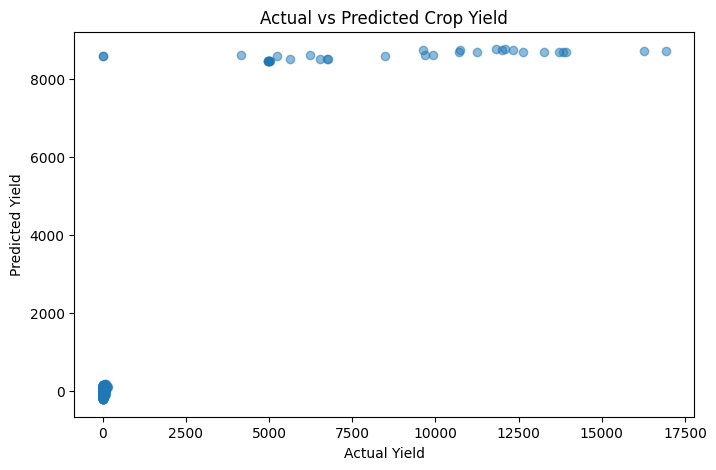

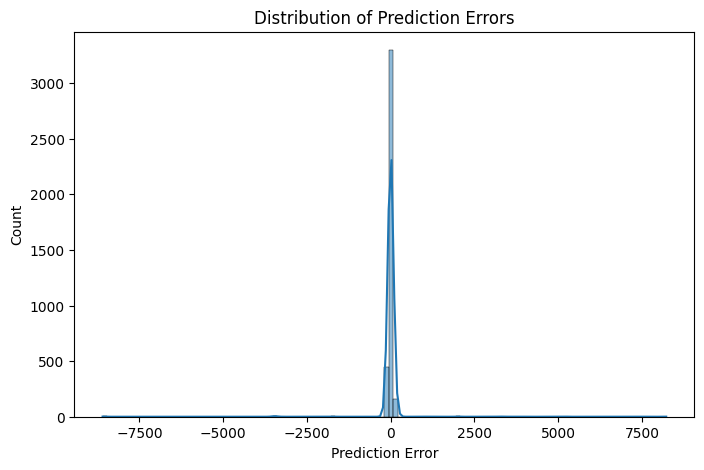


Crop Yield Prediction
Enter Crop Name: sweet corn
Enter Crop Year: 2027
Enter Season: winter
Enter State: andhra
Enter Cultivated Area (numeric): 2 acar
Please enter a valid numeric value for the area.
Enter Cultivated Area (numeric): 2
Enter Annual Rainfall (numeric): 34
Enter Fertilizer Usage (numeric): 2
Enter Pesticide Usage (numeric): 3

Predicted Crop Yield: 155.64173027109211


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Upload Dataset
uploaded = files.upload()

df = pd.read_csv('crop_yield.csv')

df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

# Data Cleaning
df = df.drop_duplicates()
df = df.dropna()

# Feature Selection
X = df[['Crop', 'Crop_Year', 'Season', 'State',
        'Area', 'Annual_Rainfall', 'Fertilizer', 'Pesticide']]

y = df['Yield']

categorical_features = ['Crop', 'Season', 'State']

numerical_features = ['Crop_Year', 'Area', 'Annual_Rainfall',
                      'Fertilizer', 'Pesticide']

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'),
         categorical_features),
        ('numerical', StandardScaler(), numerical_features)
    ]
)

# Multiple Linear Regression Model
model = Pipeline([
    ('preprocessing', preprocessor),
    ('regression', LinearRegression())
])

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Model Training with Time Measurement
start_time = time.perf_counter()

model.fit(X_train, y_train)

end_time = time.perf_counter()

training_time = end_time - start_time

# Prediction
y_pred = model.predict(X_test)

# Evaluation Metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMultiple Linear Regression Results")

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)
print("Training Time:", training_time, "seconds")

# Actual vs Predicted Results
results = pd.DataFrame({
    'Actual Yield': y_test.values,
    'Predicted Yield': y_pred
})

print("\nActual vs Predicted Values:")
print(results.head(10))

# Actual vs Predicted Graph
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title("Actual vs Predicted Crop Yield")
plt.show()

# Prediction Error Distribution
plt.figure(figsize=(8, 5))
sns.histplot(y_test - y_pred, kde=True)
plt.xlabel("Prediction Error")
plt.title("Distribution of Prediction Errors")
plt.show()

# New Crop Yield Prediction
print("\nCrop Yield Prediction")

crop = input("Enter Crop Name: ")
year = int(input("Enter Crop Year: "))
season = input("Enter Season: ")
state = input("Enter State: ")
area = float(input("Enter Cultivated Area: "))
rainfall = float(input("Enter Annual Rainfall: "))
fertilizer = float(input("Enter Fertilizer Usage: "))
pesticide = float(input("Enter Pesticide Usage: "))

new_data = pd.DataFrame({
    'Crop': [crop],
    'Crop_Year': [year],
    'Season': [season],
    'State': [state],
    'Area': [area],
    'Annual_Rainfall': [rainfall],
    'Fertilizer': [fertilizer],
    'Pesticide': [pesticide]
})

prediction = model.predict(new_data)

print("\nPredicted Crop Yield:", prediction[0])
